# Week 3 Day 5: Prophet and a yearly ARIMA, in Colab

In today's lesson you forecast the client's weekly parcels in your browser. Two tools from the lesson could not run there, and this notebook runs them.

- **Prophet** fits its curve with a compiled program called Stan. A browser cannot run that program, so Prophet runs here, on a computer Google lends you.
- **SARIMA with a yearly term.** The lesson ran the simplest seasonal ARIMA in the page. A fuller one, with one more yearly term, takes about ten seconds for each fit in the browser and well under a second here.

Press **Runtime → Run all**, or run the cells one at a time and guess before each one. It takes about 20 minutes.

**What you need from the lesson.** A forecast is judged on weeks it has not seen. The window that matters most is the one that mirrors what the client asked for: stand at the end of October 2025, forecast the next 8 weeks, and compare with what really happened. The lesson's simplest good method was **the same week last year, times this year's growth**. Every tool here is set beside it.

In [1]:
%pip install -q prophet==1.5.0

import prophet, statsmodels, pandas, numpy
print("prophet", prophet.__version__)
print("statsmodels", statsmodels.__version__)
print("pandas", pandas.__version__)
print("numpy", numpy.__version__)

prophet 1.5.0
statsmodels 0.15.0
pandas 3.1.1
numpy 2.5.5


The first line installs Prophet 1.5.0, the version this notebook was written for. The saved run printed prophet 1.5.0, statsmodels 0.15.0, pandas 3.1.1 and numpy 2.5.5. Colab's own versions may differ, and your figures can then differ a little from the saved ones. The conclusions should not.

## 1. The weekly series

The same series as the lesson: one count for each week, Monday to Sunday, from the client's two dispatch files. Nothing here says whether a parcel was late. How many weeks should there be? The lesson counted them.

In [2]:
import logging
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

# Set the environment variable DATA_DIR to a folder holding the two files to read them from there instead of GitHub.
DATA_DIR = os.environ.get("DATA_DIR")
BASE = "https://raw.githubusercontent.com/talhaturab/fde-course-notebooks/main/data/"

def data_file(name):
    return os.path.join(DATA_DIR, name) if DATA_DIR else BASE + name

sent = pd.concat([
    pd.read_csv(data_file("shipments_history.csv"), usecols=["dispatched_at"]),
    pd.read_csv(data_file("shipments_history_october.csv"), usecols=["dispatched_at"]),
])
when = pd.to_datetime(sent["dispatched_at"])
weekly = when.dt.to_period("W-SUN").dt.start_time.value_counts().sort_index()
weekly.index.freq = "W-MON"
y = weekly.to_numpy().astype(float)
print(len(weekly), "weeks, from the week of", weekly.index[0].date(), "to the week of", weekly.index[-1].date())

148 weeks, from the week of 2024-01-01 to the week of 2026-10-26


148 weeks, as in the lesson, from the first week of January 2024 to the last week of October 2026.

## 2. The window that mirrors the forecast, and the method to beat

`L = 96` means "the model has seen 96 weeks", which ends on Sunday 2 November 2025. The 8 weeks after that are the test: 3 November to 28 December 2025, last year's peak and its Christmas week.

The cell builds the lesson's method again and scores it. `mae` is the average miss in parcels a week, and `total` is how far the 8-week total was off, in percent. Do you remember roughly how far off the total was?

In [3]:
H = 8

def last_year_times_growth(seen):
    L = len(seen)
    growth = seen[-12:].sum() / seen[-64:-52].sum()
    return seen[L - 52:L - 52 + H] * growth

def score(forecast, L):
    truth = y[L:L + H]
    return round(float(np.abs(forecast - truth).mean()), 1), round(float(100 * (forecast.sum() - truth.sum()) / truth.sum()), 1)

L = 96
baseline = last_year_times_growth(y[:L])
print("truth   ", y[L:L + H].astype(int))
print("baseline", baseline.round().astype(int))
print("mae, total %:", score(baseline, L))

truth    [234 229 302 335 330 305 318  95]
baseline [224 263 297 288 311 325 321  81]
mae, total %: (19.0, -1.8)


It missed by about 19.0 parcels a week, and its 8-week total was 1.8% from the truth. That is the row to beat.

## 3. Prophet on the same window

Prophet describes a series as a **trend** (a line that may bend) plus a **yearly curve** (the season), and fits both at once. You give it a table with two columns, `ds` for the date and `y` for the count, and it gives back a forecast with a range.

It has seen the same 96 weeks, which hold one November and December. Will it get closer to last year's peak than the baseline did? Decide, then run it.

In [4]:
from prophet import Prophet

def prophet_forecast(L, mode="additive"):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, seasonality_mode=mode, interval_width=0.8)
    m.fit(pd.DataFrame({"ds": weekly.index[:L], "y": y[:L]}))
    future = pd.DataFrame({"ds": pd.date_range(weekly.index[0], periods=L + H, freq="W-MON")[L:]})
    np.random.seed(0)
    return m, m.predict(future)

model, guess = prophet_forecast(96)
print("truth  ", y[96:104].astype(int))
print("prophet", guess["yhat"].round().astype(int).to_numpy())
print("mae, total %:", score(guess["yhat"].to_numpy(), 96))

truth   [234 229 302 335 330 305 318  95]
prophet [195 212 238 270 289 276 227 163]
mae, total %: (51.6, -12.9)


Not closer. Prophet missed by about 51.6 parcels a week against the baseline's 19.0, and its total was 12.9% off. Look at the last number of each row. The true Christmas week was 95 parcels, and Prophet said 163.

**Reading the code.** `yearly_seasonality=True` asks for the yearly curve. The weekly and daily curves are switched off because each row is already a whole week. `interval_width=0.8` asks for an 80% range.

The picture shows why Christmas week went wrong.

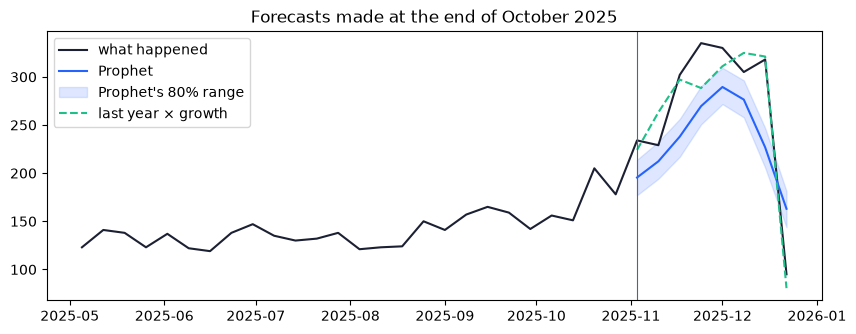

weeks inside Prophet's 80% range: 1 of 8


In [5]:
plt.figure(figsize=(10, 3.5))
plt.plot(weekly.index[70:104], y[70:104], color="#1c2033", label="what happened")
plt.plot(guess["ds"], guess["yhat"], color="#2563ff", label="Prophet")
plt.fill_between(guess["ds"], guess["yhat_lower"], guess["yhat_upper"], color="#2563ff", alpha=0.15, label="Prophet's 80% range")
plt.plot(guess["ds"], baseline, color="#1fbf8a", linestyle="--", label="last year × growth")
plt.axvline(weekly.index[96], color="#5b6178", linewidth=0.8)
plt.legend(); plt.title("Forecasts made at the end of October 2025"); plt.show()
inside = ((guess["yhat_lower"] <= y[96:104]) & (y[96:104] <= guess["yhat_upper"])).sum()
print("weeks inside Prophet's 80% range:", int(inside), "of 8")

Prophet's yearly curve is **smooth**: it is built from a few slow waves. The client's year is not smooth at Christmas. Parcels run at their highest for the year until about 21 December and then fall to a third in one week. A smooth curve cannot turn that corner, so Prophet starts coming down too early and does not come down far enough.

The second thing to read is the shaded band. Prophet called it an 80% range, and 1 of the 8 true weeks fell inside it. A range is a claim, and this is how you check one.

Prophet can be told about a known one-off drop with its `holidays` setting. This notebook leaves that to you: it would be a choice made after seeing the miss, so it would need a peak it has not seen to test it.

## 4. A season that multiplies

By default Prophet **adds** the season to the trend: the peak is so many parcels above the line. The other choice is to **multiply**: the peak is so many percent above the line. If the client is growing, which one should make the peak bigger each year? Decide, then run it.

In [6]:
model_mul, guess_mul = prophet_forecast(96, "multiplicative")
print("truth          ", y[96:104].astype(int))
print("additive       ", guess["yhat"].round().astype(int).to_numpy(), score(guess["yhat"].to_numpy(), 96))
print("multiplicative ", guess_mul["yhat"].round().astype(int).to_numpy(), score(guess_mul["yhat"].to_numpy(), 96))
print("last year × growth", baseline.round().astype(int), score(baseline, 96))

truth           [234 229 302 335 330 305 318  95]
additive        [195 212 238 270 289 276 227 163] (51.6, -12.9)
multiplicative  [202 221 252 289 313 298 239 163] (38.4, -8.0)
last year × growth [224 263 297 288 311 325 321  81] (19.0, -1.8)


Multiplying makes the peak grow with the client, and it came closer: about 38.4 parcels a week off, with a total 8.0% off. It is still behind the baseline, and Christmas week is still wrong.

This is one window. One window cannot tell you which of the two kinds of season is right for this client. It can only tell you which was closer last year.

## 5. Ten windows, not one

The lesson scored every method on ten windows of 8 weeks that do not overlap. The cell does the same for Prophet. It prints the average miss in each window for the baseline and for both Prophets, then counts in how many of the ten each Prophet beat the baseline. Only one of the ten windows holds a peak. Will Prophet do better in the other nine? Decide, then run it. It takes about half a minute.

In [7]:
windows = list(range(64, 137, 8))
table = pd.DataFrame(index=[str(weekly.index[L].date()) for L in windows])
table["last year × growth"] = [score(last_year_times_growth(y[:L]), L)[0] for L in windows]
table["prophet, additive"] = [score(prophet_forecast(L)[1]["yhat"].to_numpy(), L)[0] for L in windows]
table["prophet, multiplicative"] = [score(prophet_forecast(L, "multiplicative")[1]["yhat"].to_numpy(), L)[0] for L in windows]
print(table)
print(table.mean().round(1))
print("windows where it beat the baseline:", int((table["prophet, additive"] < table["last year × growth"]).sum()), "and", int((table["prophet, multiplicative"] < table["last year × growth"]).sum()), "of 10")

            last year × growth  prophet, additive  prophet, multiplicative
2025-03-24                22.4               12.1                     11.8
2025-05-19                14.7               14.4                     14.8
2025-07-14                 8.8                9.9                     10.4
2025-09-08                12.4               17.9                     16.6
2025-11-03                19.0               51.6                     38.4
2025-12-29                25.9               17.4                     24.9
2026-02-23                16.7               11.8                     12.8
2026-04-20                19.6                7.0                      7.1
2026-06-15                15.2                8.7                     12.7
2026-08-10                19.7               10.3                     10.8
last year × growth         17.4
prophet, additive          16.1
prophet, multiplicative    16.0
dtype: float64
windows where it beat the baseline: 7 and 6 of 10


Yes. Away from the peak Prophet is the better of the two: it beat the baseline in 7 of the ten windows (the multiplicative one in 6), and its average miss over all ten is 16.1 parcels a week against the baseline's 17.4.

Put the two findings together. In ordinary weeks Prophet's bending trend follows the client better than "last year times growth". In the one window that looks like the forecast the client asked for, the baseline was far closer. Which one you would use depends on which weeks you are forecasting. Ten windows, one of them a peak, cannot settle more than that.

## 6. SARIMA with a yearly term

The lesson's seasonal ARIMA took the difference from the same week a year earlier and stopped there. The usual fuller form adds one yearly term on top, written (0,1,1)(0,1,1) with a season of 52. Each fit takes about ten seconds in the browser, which is why it is here.

It has more to estimate from the same 96 weeks. Will the extra term change the forecast for last year's peak? Decide, then run it.

In [8]:
from statsmodels.tsa.arima.model import ARIMA

plain = ARIMA(y[:96], order=(0, 1, 1), seasonal_order=(0, 1, 0, 52)).fit().forecast(H)
fuller = ARIMA(y[:96], order=(0, 1, 1), seasonal_order=(0, 1, 1, 52)).fit().forecast(H)
print("truth ", y[96:104].astype(int))
print("plain ", plain.round().astype(int), score(plain, 96))
print("fuller", fuller.round().astype(int), score(fuller, 96))

truth  [234 229 302 335 330 305 318  95]
plain  [209 240 267 260 278 289 286  95] (30.7, -10.4)
fuller [209 240 267 260 278 289 286  95] (30.7, -10.4)


It hardly changes anything: both miss by about 30.7 parcels a week and both totals are 10.4% off. After the yearly difference, 96 weeks leave only 44 values, all of them from one year's change. That is too little to estimate a yearly term from.

Both forecasts are the same kind of thing: last year's weeks **plus** a fixed number of parcels. The baseline is last year's weeks **times** a growth rate. On last year's peak, "times" was closer.

## 7. The forecast for November and December 2026

Now every method sees all 148 weeks and forecasts the 8 weeks from 2 November to 27 December 2026. **Nobody can score these yet:** those weeks have not happened in the client's files. Before you run it: will the methods agree?

In [9]:
future_weeks = pd.date_range(weekly.index[-1] + pd.Timedelta(days=7), periods=H, freq="W-MON")
final = pd.DataFrame(index=[d.strftime("%d %b") for d in future_weeks])
final["last year × growth"] = last_year_times_growth(y)
final["prophet, additive"] = prophet_forecast(len(y))[1]["yhat"].to_numpy()
final["prophet, multiplicative"] = prophet_forecast(len(y), "multiplicative")[1]["yhat"].to_numpy()
final["sarima, plain"] = ARIMA(y, order=(0, 1, 1), seasonal_order=(0, 1, 0, 52)).fit().forecast(H)
final["sarima, fuller"] = ARIMA(y, order=(0, 1, 1), seasonal_order=(0, 1, 1, 52)).fit().forecast(H)
print(final.round().astype(int))
print(final.sum().round().astype(int))

        last year × growth  prophet, additive  prophet, multiplicative  \
02 Nov                 306                255                      272   
09 Nov                 299                278                      307   
16 Nov                 395                311                      356   
23 Nov                 438                350                      412   
30 Nov                 431                373                      445   
07 Dec                 398                359                      422   
14 Dec                 415                303                      339   
21 Dec                 124                230                      233   

        sarima, plain  sarima, fuller  
02 Nov            284             273  
09 Nov            279             286  
16 Nov            352             336  
23 Nov            385             349  
30 Nov            380             355  
07 Dec            355             348  
14 Dec            368             353  
21 Dec       

They do not agree. The 8-week totals run from about 2,450 to about 2,810 parcels. The methods that multiply the season sit at the top, and the ones that add it sit at the bottom.

That gap is the honest size of what is not known. It comes from one question the data cannot yet answer: does the client's peak grow in proportion to the business, or by a fixed number of parcels? The client has had two peaks. Only one of them could be forecast from an earlier one, and on that one, "in proportion" was closer.

So the forecast on the model card is the lesson's: the same week last year, times this year's growth, with its range. This notebook adds one sentence to the card's limits: other reasonable methods come out up to about 13% lower for the 8 weeks, and December's real counts will show which kind was right.

**What to take from this notebook.** Prophet is quick to fit and good in ordinary weeks, its smooth yearly curve misses a one-week drop, and its range was too narrow at the peak. A fuller SARIMA needs more years than this client has. A method's name does not make it better: score it on the window that looks like your forecast.